#### Coherence(x와 y의 일관성 차트)
    - 서로다른 두 신호와 특정 주파수영역에서 얼마나 비슷한 패턴으로 연관되어 움직이는지를 0과 1사이의 값으로 나타낸 지표
    - 수치해석(0~1)
        - 0에 가까움 : 해당 주파수에서 두 신호가 매우 강한 선형적 관계를 가짐
        - 1에 가까움 : 해당 주파수에서 두 신호는 아무 관계가 없다. 노이즈
    - 활용
        - 음향 및 진동 분석 : 원인 규명
        - 뇌파 분석
        - 제어 시스템

In [1]:
import matplotlib.pyplot as plt
import numpy as np

(array([1.05261467e-02, 8.17493796e-02, 3.44868298e-02, 1.00988466e-02,
        8.86570907e-02, 8.35536913e-02, 3.96283095e-02, 1.49827437e-04,
        5.23899798e-02, 6.18009735e-02, 4.81149723e-04, 1.07881319e-01,
        4.76400307e-03, 2.35046722e-02, 3.11082286e-02, 1.21122497e-02,
        2.94033822e-02, 1.56641375e-03, 4.60786533e-02, 2.60293817e-02,
        3.86385803e-02, 1.95688802e-02, 2.65801120e-02, 4.64583242e-02,
        7.41170899e-03, 3.06861066e-02, 7.04618634e-02, 4.73371914e-02,
        2.74553427e-02, 1.95061264e-02, 2.81001125e-02, 7.94607582e-02,
        1.85588730e-02, 1.20524728e-01, 1.85471519e-01, 2.77500386e-02,
        6.86894862e-02, 1.14818476e-01, 3.09707850e-02, 1.00734523e-03,
        4.53278388e-04, 2.28691801e-02, 1.90732786e-02, 9.56655024e-02,
        5.58720039e-03, 7.07054660e-02, 1.27985779e-01, 4.26115107e-02,
        4.86263166e-02, 1.18069488e-02, 4.07571352e-03, 2.38409769e-02,
        4.45946195e-02, 2.75175781e-02, 8.24318106e-02, 1.068366

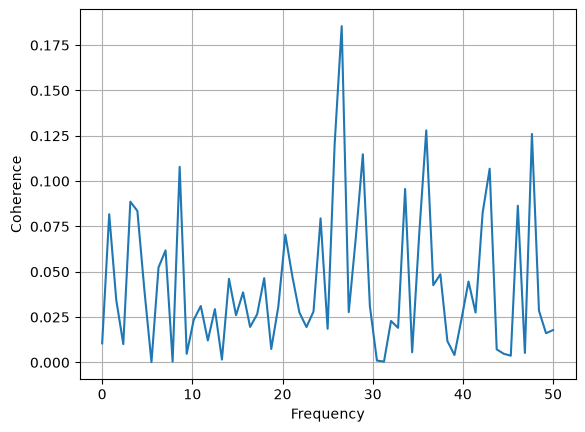

In [5]:
# 신호 데이터 생성
dt = 0.01
t = np.arange(0, 30, dt)
n1 = np.random.randn(len(t))
n2 = np.random.randn(len(t))

s1 = 1.5 * np.sin(2 *np.pi * 10 * t) + n1
s2 = np.cos(np.pi * t) + n2

plt.cohere(s1, s2**2, NFFT=128, Fs = 1.0/dt)

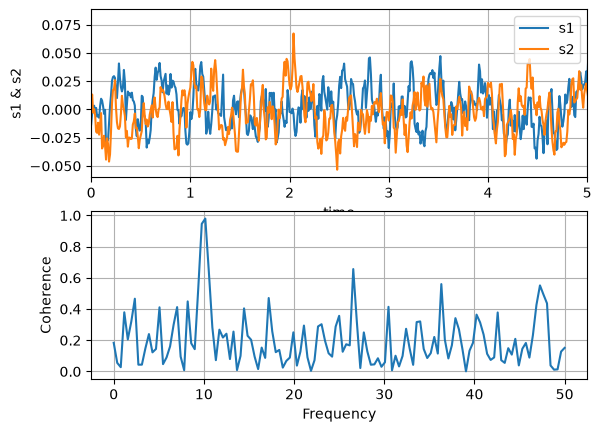

In [11]:
# 신호 데이터 생성
dt = 0.01
t = np.arange(0, 30, dt)
n1 = np.random.randn(len(t))
n2 = np.random.randn(len(t))
r = np.exp(-t/0.05)

c1 = np.convolve(n1,r,mode='same') * dt
c2 = np.convolve(n2,r,mode='same') * dt

s1 = 0.01 * np.sin(2 *np.pi * 10 * t) + c1
s2 = 0.01 * np.sin(2 *np.pi * 10 * t) + c2

plt.subplot(211)
plt.plot(t,s1, label='s1')
plt.plot(t,s2, label='s2')
plt.xlim(0,5)
plt.xlabel('time')
plt.ylabel('s1 & s2')
plt.grid(True)
plt.legend()

plt.subplot(212)
plt.cohere(s1,s2,NFFT=256,Fs=1/dt);